# `dbt` Weather & Flight Project
April 22, 2026<br>

Group 4 | Eido, Kai, Dasha<br>

---

## Weather Event
During Winter Storm Elliott (December 21–28, 2022), a massive Blizzard and "flash freeze" devastated U.S. aviation. Temperatures plunged by $15$ to $20^\circ\text{C}$ in hours, turning wet runways into ice sheets. Combined with hurricane-force winds, the storm paralyzed the busiest travel week of the year.

[Unraveling Extreme Weather Impacts on Air Transportation and Passenger Delays using Location-based Data](https://arxiv.org/abs/2304.12084)
![Alt-text](images/dbt_article.png)

---
## Pipeline
Python - PostgreSQL - dbt - Pandas

---
## Workflow:
1. Data Acquisition (Extraction)
- Weather Data: Pulled historical meteorological records (temperature, wind speed, precipitation) via the [Meteostat API](https://dev.meteostat.net/api).
- Flight Data: Extracted [US domestic flight](https://transtats.bts.gov) flight performance metrics, focusing on cancellations and delays.

2. Infrastructure & Version Control
- Repository Management: Initialized a new GitHub repository for version control.
- dbtCloud: Connected the repository to `dbt Cloud` to enable version-controlled data transformations and documentation.

3. Data Transformation (`dbt Cloud`)
- Staging Layer: Created cleaned, standardized views of raw data + dropped several staging tables later. Used DBeaver to control results.
- Preparation Layer: Developed prep_final model to join weather and flight datasets on a shared date/airport columns.

4. Analysis & Insight (PostgreSQL + Python)
- Exploratory Data Analysis (EDA): Used  Python to connect to the PostgreSQL data warehouse.
- Hypothesis Testing: Conducted Welch’s t-tests and calculated 95% Confidence Intervals to statistically validate the impact of the storm (temperature and wind spead mainly).
- Data Visualization: Built correlation heatmaps and time-series trend lines using Seaborn and Matplotlib to communicate findings.

---

## Selected Airports
|Airport|Primary Weather Impact|Operational Result|
|---|-----|--------|
|ORD (Chicago)|Blizzard & −40∘C wind chills|800+ flights cancelled early in the event|
|JFK (New York)|100 km/h winds & record cold|25%+ cancellation rate on peak days|
|EWR (Newark)|Flash freeze & infrastructure failure|Massive delays due to frozen ground equipment|
|BOS (Boston)|Coastal flooding & heavy snow|64% of schedule grounded on the worst day|
|ATL (Atlanta)|Freezing rain in a southern hub|500+ daily cancellations; huge ripple effect|

### Selected Airports: Map
![Alt-text](images/dbt_map.png)

---

# 1. Connect to database in PostgreSQL and load and check the data:

In [1]:
import pandas as pd
from sqlalchemy import create_engine
from dotenv import dotenv_values

config = dotenv_values()

url = f"postgresql://{config['POSTGRES_USER']}:{config['POSTGRES_PASS']}@{config['POSTGRES_HOST']}:{config['POSTGRES_PORT']}/{config['POSTGRES_DB']}"
engine = create_engine(url)

query = """
SELECT *
FROM aero_insights.prep_final
ORDER BY date, airport_code
"""

df = pd.read_sql(query, engine)

In [2]:
df.shape
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype          
---  ------                 --------------  -----          
 0   airport_code           140 non-null    str            
 1   date                   140 non-null    object         
 2   flights_out            140 non-null    int64          
 3   flights_in             140 non-null    int64          
 4   total_flights          140 non-null    int64          
 5   origin_cancelled_rate  140 non-null    float64        
 6   dest_cancelled_rate    140 non-null    float64        
 7   total_cancelled_num    140 non-null    int64          
 8   total_diverted_num     140 non-null    int64          
 9   origin_diverted_rate   140 non-null    float64        
 10  dest_diverted_rate     140 non-null    float64        
 11  avg_dep_delay          140 non-null    timedelta64[us]
 12  avg_arr_delay          140 non-null    timedelta64[us]
 13  s

airport_code               0
date                       0
flights_out                0
flights_in                 0
total_flights              0
origin_cancelled_rate      0
dest_cancelled_rate        0
total_cancelled_num        0
total_diverted_num         0
origin_diverted_rate       0
dest_diverted_rate         0
avg_dep_delay              0
avg_arr_delay              0
station_id                 0
avg_temp_c                 0
min_temp_c                 0
max_temp_c                 0
precipitation_mm           0
max_snow_mm               28
avg_wind_direction       140
avg_wind_speed             0
avg_peakgust             140
avg_pressure_hpa           0
sun_minutes              140
dtype: int64

# 2. Descriptive Statistics

## 2.1. Descriptive statistics for the airports performance on average in December 2022:

In [3]:
# stats for flights

df.groupby("airport_code")[[
    "total_flights",
    "total_cancelled_num",
    "origin_cancelled_rate",
    "dest_cancelled_rate",
    "avg_dep_delay",
    "avg_arr_delay"
]].agg(["mean", "std", "min", "max", "sum"]).T

airport_code                                   ATL                       BOS  \
total_flights         mean              112.357143                718.571429   
                      std                 9.153887                 88.777053   
                      min                       89                       508   
                      max                      122                       810   
                      sum                     3146                     20120   
total_cancelled_num   mean                     3.0                 23.714286   
                      std                 5.962848                 41.019288   
                      min                        0                         0   
                      max                       19                       197   
                      sum                       84                       664   
origin_cancelled_rate mean                2.929643                    3.5925   
                      std                 6.065335                  6.064061   
                      min                      0.0                       0.0   
                      max                    22.22                      26.8   
                      sum                    82.03                    100.59   
dest_cancelled_rate   mean                3.084643                  3.514643   
                      std                 6.486163                  6.046634   
                      min                      0.0                       0.0   
                      max                    22.22                     27.55   
                      sum                    86.37                     98.41   
avg_dep_delay         mean  0 days 00:20:04.355025    0 days 00:20:02.771529   
                      std   0 days 00:15:12.095023    0 days 00:17:27.594401   
                      min   0 days 00:04:47.213115    0 days 00:00:16.530612   
                      max   0 days 00:50:31.153846    0 days 01:06:03.196721   
                      sum   0 days 09:22:01.940702    0 days 09:21:17.602825   
avg_arr_delay         mean  0 days 00:13:53.458355    0 days 00:16:45.454399   
                      std   0 days 00:21:18.109215    0 days 00:19:58.133279   
                      min        -1 days +23:45:15  -1 days +23:54:40.874036   
                      max   0 days 01:06:33.191489    0 days 01:04:10.400000   
                      sum   0 days 06:28:56.833950    0 days 07:49:12.723176   

airport_code                                     EWR  \
total_flights         mean                740.214286   
                      std                  41.541908   
                      min                        642   
                      max                        786   
                      sum                      20726   
total_cancelled_num   mean                 22.178571   
                      std                  44.433099   
                      min                          0   
                      max                        157   
                      sum                        621   
origin_cancelled_rate mean                  3.149286   
                      std                   6.717769   
                      min                        0.0   
                      max                      23.84   
                      sum                      88.18   
dest_cancelled_rate   mean                  3.197857   
                      std                     6.4529   
                      min                        0.0   
                      max                      25.08   
                      sum                      89.54   
avg_dep_delay         mean    0 days 00:25:00.816465   
                      std     0 days 00:22:20.654285   
                      min     0 days 00:05:42.724936   
                      max     0 days 01:33:39.595142   
                      sum     0 days 11:40:22.861030   
avg_arr_delay         mean    0 days 00:20:23.763176   
       

## 2.2. Descriptive statistics for weather in the given airports in December 2022:

In [4]:
df.groupby("airport_code")[[
    "avg_temp_c",
    "min_temp_c",
    "max_temp_c",
    "precipitation_mm",
    "max_snow_mm",
    "avg_wind_speed",
    "avg_peakgust"
]].agg(["mean", "std", "min", "max", "sum"]).T

airport_code                 ATL        BOS        EWR        JFK        ORD
avg_temp_c       mean   7.814286   2.557143   3.278571      2.975  -2.260714
                 std    6.541475   4.819284   5.265355   5.203106   6.717602
                 min        -9.6       -7.6      -11.4      -11.6      -19.9
                 max        20.0       11.4       14.2       12.8        4.9
                 sum       218.8       71.6       91.8       83.3      -63.3
min_temp_c       mean   3.896429     -1.225  -1.132143  -0.860714     -5.825
                 std    7.466393   4.491113   5.368913   5.410918   7.654126
                 min       -13.2      -11.6      -13.2      -13.8      -22.1
                 max        16.1        8.9       12.2       12.2        2.8
                 sum       109.1      -34.3      -31.7      -24.1     -163.1
max_temp_c       mean  12.328571   5.971429   7.135714   6.410714   1.142857
                 std     5.80497   5.149819   5.154876   5.174964   6.694576
                 min        -2.7       -6.6       -8.2       -8.8      -18.2
                 max        25.6       15.0       15.6       13.9       11.7
                 sum       345.2      167.2      199.8      179.5       32.0
precipitation_mm mean   3.017857   3.089286      3.875   2.632143   1.964286
                 std    6.235267   7.671416   7.629894   4.882778    6.90653
                 min         0.0        0.0        0.0        0.0        0.0
                 max        21.1       32.5       32.0       17.3       35.1
                 sum        84.5       86.5      108.5       73.7       55.0
max_snow_mm      mean        0.0        NaN        0.0        0.0       0.75
                 std         0.0        NaN        0.0        0.0   1.322876
                 min         0.0        NaN        0.0        0.0        0.0
                 max         0.0        NaN        0.0        0.0        3.0
                 sum         0.0        0.0        0.0        0.0       21.0
avg_wind_speed   mean  13.457143  21.792857  17.678571  22.496429  17.314286
                 std    6.137887   8.062025   6.752852   8.802966   7.420678
                 min         5.0        9.7        6.1        7.6        6.1
                 max        34.2       46.8       34.9       49.0       34.9
                 sum       376.8      610.2      495.0      629.9      484.8
avg_peakgust     mean        NaN        NaN        NaN        NaN        NaN
                 std         NaN        NaN        NaN        NaN        NaN
                 min         NaN        NaN        NaN        NaN        NaN
                 max         NaN        NaN        NaN        NaN        NaN
                 sum           0          0          0          0          0

### H1 Weather event detection. Do we see the weather event in our data?

In [5]:


df_event = df[
    (pd.to_datetime(df["date"]) >= pd.Timestamp("2022-12-22")) &
    (pd.to_datetime(df["date"]) <= pd.Timestamp("2022-12-28"))
]

df_event.groupby("airport_code")[[
    "avg_temp_c",
    "precipitation_mm",
    "avg_wind_speed"
]].mean()

,avg_temp_c,precipitation_mm,avg_wind_speed
airport_code,,,
ATL,-0.057143,0.128571,15.057143
BOS,-1.128571,2.914286,23.814286
EWR,-1.371429,5.585714,22.128571
JFK,-1.728571,1.600000,27.728571
ORD,-9.942857,0.328571,22.000000


### Checking non event as comparison


In [6]:

df_non_event = df[
    (pd.to_datetime(df["date"]) <= pd.Timestamp("2022-12-22")) |
    (pd.to_datetime(df["date"]) >= pd.Timestamp("2022-12-28"))
]

df_non_event.groupby("airport_code")[[
    "avg_temp_c",
    "precipitation_mm",
    "avg_wind_speed"
]].mean()

,avg_temp_c,precipitation_mm,avg_wind_speed
airport_code,,,
ATL,10.021739,3.647826,12.613043
BOS,3.539130,3.030435,20.643478
EWR,4.669565,3.326087,16.026087
JFK,4.360870,2.873913,20.452174
ORD,0.165217,2.391304,16.326087


## 2.3 Airport stats for the identified storm event: 


In [8]:
df_event = df[
    (pd.to_datetime(df["date"]) >= pd.Timestamp("2022-12-22")) &
    (pd.to_datetime(df["date"]) <= pd.Timestamp("2022-12-28"))
]

df_event.groupby("airport_code")[[
    "total_flights",
    "origin_cancelled_rate",
    "dest_cancelled_rate",
    "total_cancelled_num",
    "avg_dep_delay",
    "avg_arr_delay"
]].mean()

,total_flights,origin_cancelled_rate,dest_cancelled_rate,total_cancelled_num,avg_dep_delay,avg_arr_delay
airport_code,,,,,,
ATL,102.428571,10.987143,11.581429,11.142857,0 days 00:38:13.670070,0 days 00:37:25.588646
BOS,641.857143,11.958571,11.717143,76.714286,0 days 00:42:57.000569,0 days 00:43:59.392459
EWR,715.857143,11.402857,11.442857,79.285714,0 days 00:54:52.023722,0 days 00:54:10.175358
JFK,620.285714,12.585714,13.200000,78.428571,0 days 00:49:33.649700,0 days 00:49:32.533636
ORD,1298.142857,14.542857,15.227143,198.142857,0 days 00:55:02.312605,0 days 00:40:35.945763


## 2.3 b Airport stats OUTSIDE OF THE the identified storm event: 

In [9]:

df_no_event_airport = df[
    (pd.to_datetime(df["date"]) <= pd.Timestamp("2022-12-22")) |
    (pd.to_datetime(df["date"]) >= pd.Timestamp("2022-12-28"))
]

df_no_event_airport.groupby("airport_code")[[
    "total_flights",
    "origin_cancelled_rate",
    "dest_cancelled_rate",
    "total_cancelled_num",
    "avg_dep_delay",
    "avg_arr_delay"
]].mean()

,total_flights,origin_cancelled_rate,dest_cancelled_rate,total_cancelled_num,avg_dep_delay,avg_arr_delay
airport_code,,,,,,
ATL,115.086957,0.687391,0.542609,0.695652,0 days 00:15:17.605999,0 days 00:07:11.577196
BOS,739.913043,1.311304,1.312609,9.608696,0 days 00:13:52.161991,0 days 00:09:24.593882
EWR,747.913043,0.549130,0.572609,4.173913,0 days 00:16:11.565589,0 days 00:11:11.350752
JFK,750.739130,0.591739,0.714783,4.739130,0 days 00:14:12.307169,0 days 00:10:55.049890
ORD,1371.217391,1.907391,2.019130,27.478261,0 days 00:13:21.957609,0 days 00:06:10.487081


In [10]:
# now same per airport

#H2 Weather event detection. Do we see the weather event in airports performance in our data?

df["period"] = df["date"].apply(
    lambda x: "event" if "2022-12-22" <= str(x)[:10] <= "2022-12-28" else "non_event"
)

In [11]:
import pandas as pd
import numpy as np
from scipy import stats

In [12]:
df["date"] = pd.to_datetime(df["date"])

df["period"] = np.where(
    (df["date"] >= pd.Timestamp("2022-12-22")) &
    (df["date"] <= pd.Timestamp("2022-12-28")),
    "event",
    "non_event"
)

In [13]:
airports = ["ATL", "BOS", "EWR", "JFK", "ORD"]
df = df[df["airport_code"].isin(airports)].copy()


---

# 3. Hypotesis testing
## 3.1 H1: The Winter Storm Elliott is visible in the weather data as a statistically significant deviation in temperature between the event and non-event period.

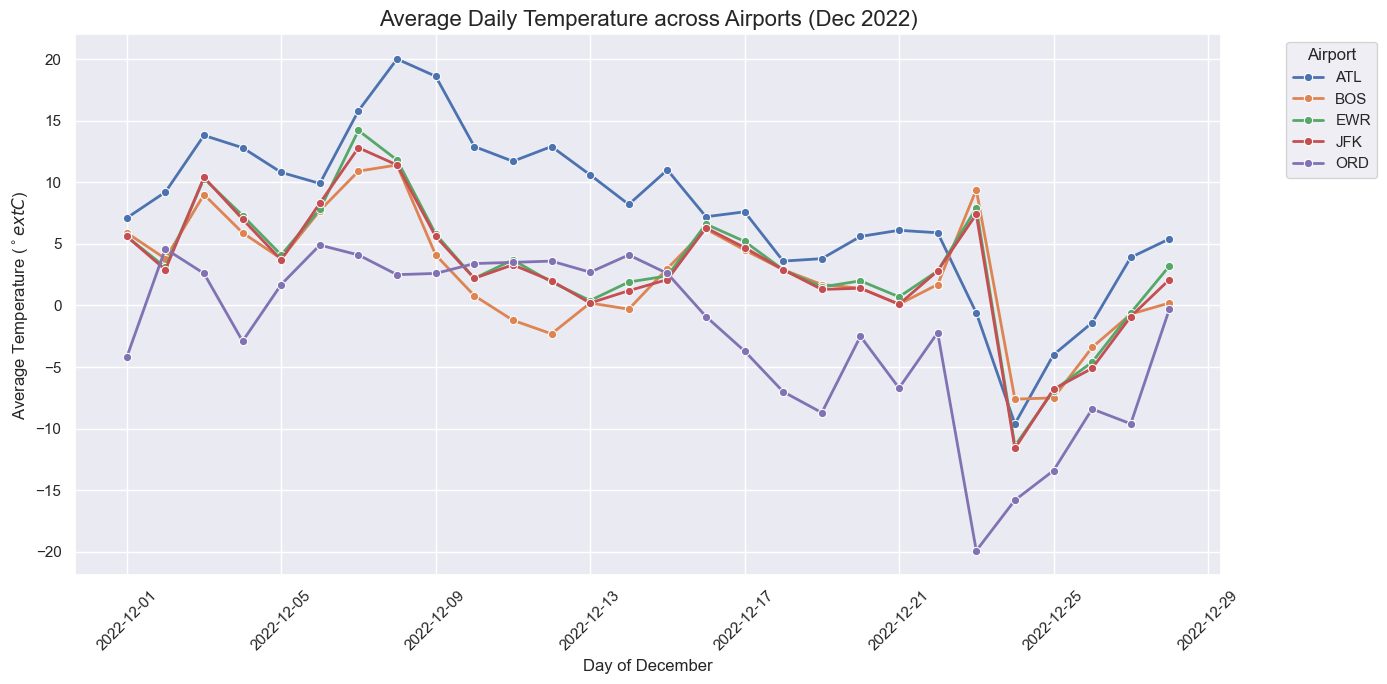

In [14]:
# !

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure the date column is in the correct datetime format
df['date'] = pd.to_datetime(df['date'])

# 2. Set the visual style
sns.set_theme(style="darkgrid")

# 3. Create the line plot
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(
    data=df, 
    x='date', 
    y='avg_temp_c', 
    hue='airport_code', 
    marker='o',      # Adds dots to each day
    linewidth=2      # Makes the lines easier to see
)

# 4. Refine the labels and title
plt.title('Average Daily Temperature across Airports (Dec 2022)', fontsize=16)
plt.xlabel('Day of December', fontsize=12)
plt.ylabel('Average Temperature ($^\circ\text{C}$)', fontsize=12)

# 5. Improve X-axis readability (prevents overlapping dates)
plt.xticks(rotation=45)

# 6. Move the legend outside the plot so it doesn't cover the lines
plt.legend(title='Airport', bbox_to_anchor=(1.05, 1), loc='upper left')

# 7. Save the result
plt.tight_layout()
plt.savefig('temp_trends_december.png')

### How:
To test this hypothesis, we compared average temperature values between the event period (Dec 22–28, 2022) and the non-event period using a Welch’s t-test.

### Why:
This test was chosen because it does not assume equal variances between groups.

### IN DETAIL:
- Why this test: We used Welch’s t-test because we compare the means of two independent groups:
    - event period
    - non-event period
    - What Welch’s t-test does: It tests whether the difference in average values between two groups is larger than what we would expect from random variation alone.
    - Why not a standard t-test: Welch’s t-test is better when the two groups may have different variances and different group sizes.
- That fits our data:
	- 35 event observations
	- 105 non-event observations
	- When to use Welch’s t-test:
- Use it when:
	- you compare two groups
	- the variable is numeric
	- observations are independent
	- equal variance cannot safely be assumed

#### We additionally calculated:
- 95% confidence intervals for the mean difference
- effect size using Cohen’s d (shows the size of the effect, not just whether it is significant)

In [15]:
def cohens_d_welch(x, y):
    x = pd.Series(x).dropna()
    y = pd.Series(y).dropna()
    nx, ny = len(x), len(y)
    sx2, sy2 = x.var(ddof=1), y.var(ddof=1)
    pooled = np.sqrt(((nx - 1) * sx2 + (ny - 1) * sy2) / (nx + ny - 2))
    return (x.mean() - y.mean()) / pooled if pooled != 0 else np.nan


def welch_ci(x, y, alpha=0.05):
    x = pd.Series(x).dropna()
    y = pd.Series(y).dropna()
    nx, ny = len(x), len(y)
    mx, my = x.mean(), y.mean()
    vx, vy = x.var(ddof=1), y.var(ddof=1)

    diff = mx - my
    se = np.sqrt(vx / nx + vy / ny)

    df_num = (vx / nx + vy / ny) ** 2
    df_den = ((vx / nx) ** 2) / (nx - 1) + ((vy / ny) ** 2) / (ny - 1)
    df_welch = df_num / df_den

    t_crit = stats.t.ppf(1 - alpha / 2, df_welch)
    ci_low = diff - t_crit * se
    ci_high = diff + t_crit * se
    return diff, ci_low, ci_high, df_welch


def run_welch_test(data, metric, group_col="period", g1="event", g2="non_event"):
    x = data.loc[data[group_col] == g1, metric].dropna()
    y = data.loc[data[group_col] == g2, metric].dropna()

    t_stat, p_val = stats.ttest_ind(x, y, equal_var=False, nan_policy="omit")
    diff, ci_low, ci_high, df_welch = welch_ci(x, y)
    d = cohens_d_welch(x, y)

    return {
        "metric": metric,
        "n_event": len(x),
        "n_non_event": len(y),
        "mean_event": x.mean(),
        "mean_non_event": y.mean(),
        "mean_diff_event_minus_non_event": diff,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "t_stat": t_stat,
        "df_welch": df_welch,
        "p_value": p_val,
        "cohens_d": d
    }

In [17]:
run_welch_test(df, metric="avg_temp_c")

{'metric': 'avg_temp_c',
 'n_event': 35,
 'n_non_event': 105,
 'mean_event': np.float64(-2.845714285714286),
 'mean_non_event': np.float64(4.779047619047619),
 'mean_diff_event_minus_non_event': np.float64(-7.624761904761905),
 'ci_low': np.float64(-10.211275487481258),
 'ci_high': np.float64(-5.038248322042552),
 't_stat': np.float64(-5.93166731168855),
 'df_welch': np.float64(46.620623777632744),
 'p_value': np.float64(3.506962328149214e-07),
 'cohens_d': np.float64(-1.3528613987819904)}

## RESULTS:
The analysis shows a statistically significant difference in average temperature between the event and non-event periods.

- Mean temperature (event): -2.85°C  
- Mean temperature (non-event): 4.78°C  
- Mean difference: -7.62°C  # HERE
- 95% Confidence Interval: [-10.21, -5.04]  
- t-statistic: -5.93  
- Degrees of freedom: 46.62  
- p-value: < 0.001  # REMEMBER: If p < 0.05, the difference is unlikely to be due to chance alone.
- Effect size (Cohen’s d): -1.35

## Interpretation:
* The temperature during the event period is significantly lower than during the non-event period.
* The confidence interval does not include zero, confirming that the difference is statistically robust.
* The p-value is far below the 0.05 threshold, indicating strong statistical evidence against the null hypothesis.
* The effect size (Cohen’s d = -1.35) is large, suggesting that the difference is not only statistically significant but also practically meaningful.

# CONCLUSION:
The hypothesis is clearly confirmed.

* The weather event is strongly reflected in the temperature data, with a large and statistically significant drop in temperature during the event period.
* This provides clear evidence that the selected time window captures a real and impactful weather event.

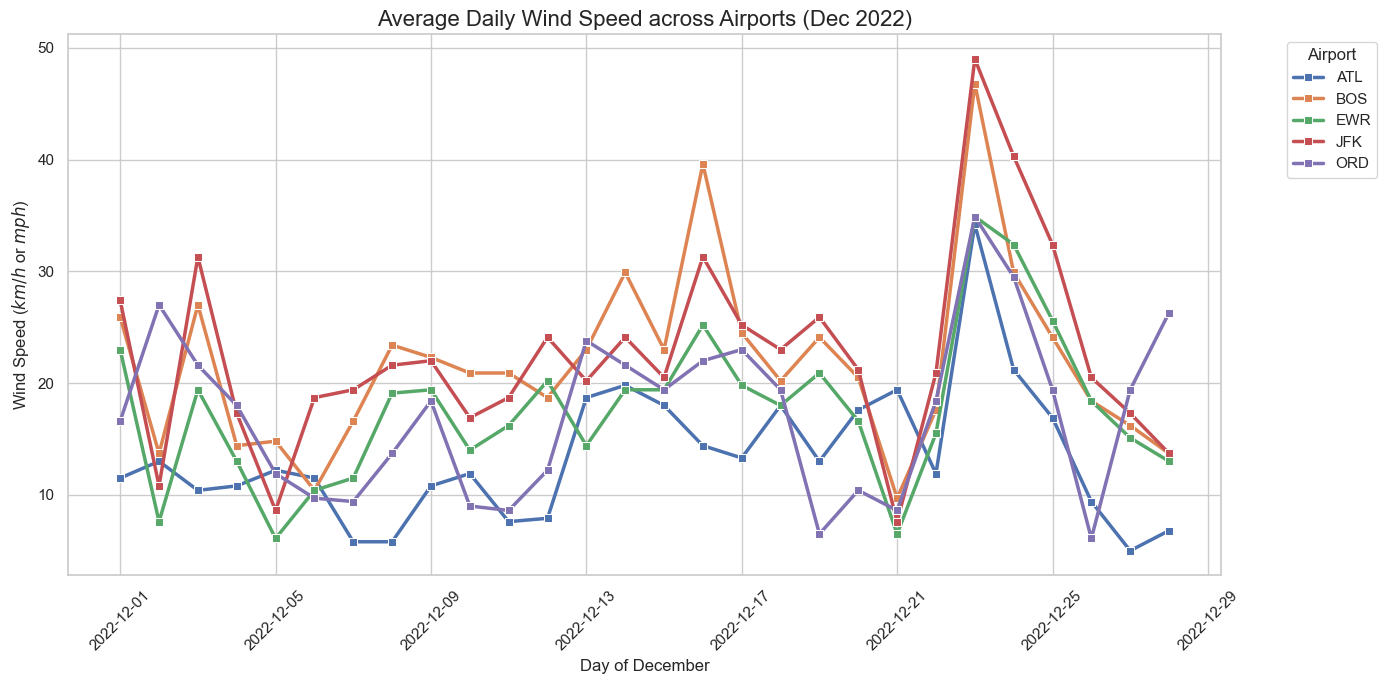

In [18]:
# ADDITIONALLY we checked for wind speed to find correlations: 

# 1. Ensure date is datetime
df['date'] = pd.to_datetime(df['date'])

# 2. Set the visual style
sns.set_theme(style="whitegrid")

# 3. Create the line plot
plt.figure(figsize=(14, 7))
wind_plot = sns.lineplot(
    data=df, 
    x='date', 
    y='avg_wind_speed', 
    hue='airport_code', 
    marker='s',      # Using 's' (square) to differentiate from the temperature plot
    linewidth=2.5
)

# 4. Formatting
plt.title('Average Daily Wind Speed across Airports (Dec 2022)', fontsize=16)
plt.xlabel('Day of December', fontsize=12)
plt.ylabel('Wind Speed ($km/h$ or $mph$)', fontsize=12) # Use the unit relevant to your data

# 5. Improve X-axis 
plt.xticks(rotation=45)

# 6. Legend outside
plt.legend(title='Airport', bbox_to_anchor=(1.05, 1), loc='upper left')

# 7. Save and show
plt.tight_layout()
plt.savefig('wind_speed_trends.png')

## H1 OVERALL RESULTS SUMMARY:

The weather event is clearly visible in the data.
- temperature dropped significantly
- wind speeds increased
- the event window captures a real weather anomaly

---


## 3.2 H2 – Impact of Weather Event on Flight Disruptions

Flight disruptions, measured by cancellation rates, are significantly higher during the weather event period compared to the non-event period.

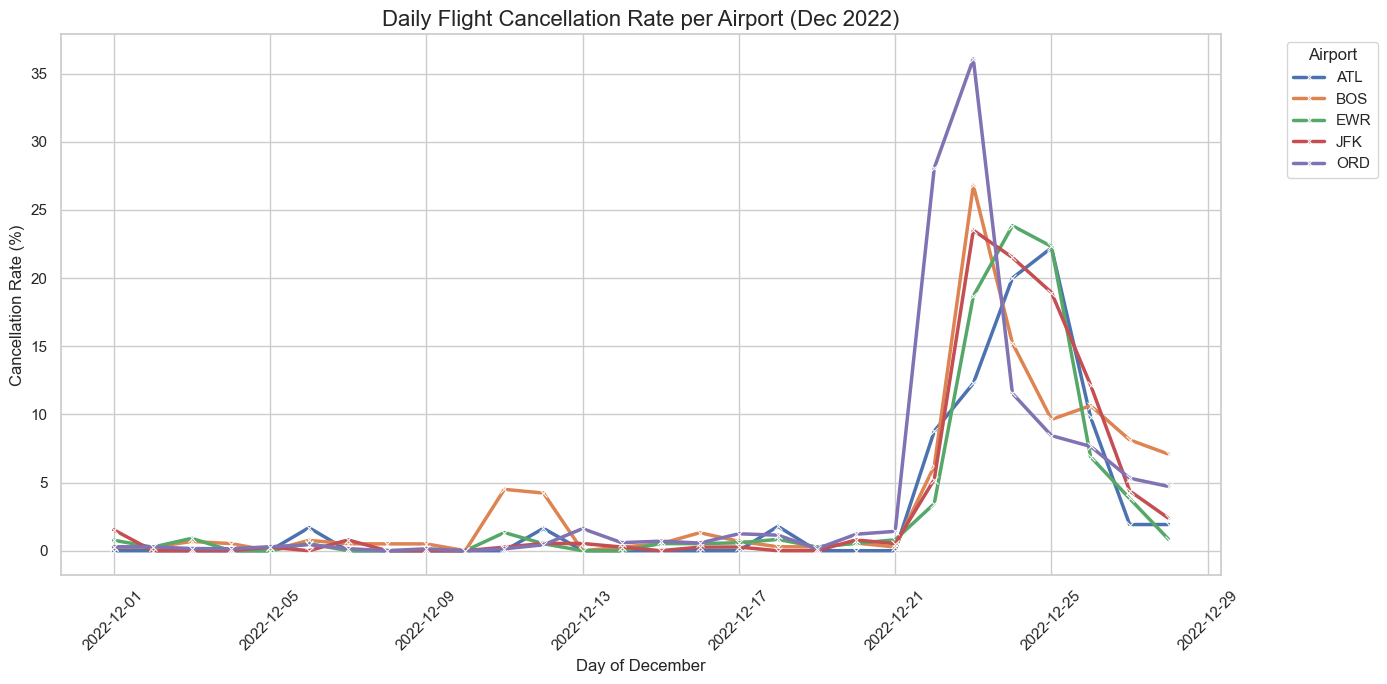

In [19]:

# First, lets check the cancellation patterns

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure date is datetime
df['date'] = pd.to_datetime(df['date'])

# 2. Set the visual style
sns.set_theme(style="whitegrid")

# 3. Create the line plot
plt.figure(figsize=(14, 7))
cancel_plot = sns.lineplot(
    data=df, 
    x='date', 
    y='origin_cancelled_rate', # Tracking the percentage of flights cancelled
    hue='airport_code', 
    marker='x',      # Using 'x' markers to differentiate
    linewidth=2.5
)

# 4. Formatting
plt.title('Daily Flight Cancellation Rate per Airport (Dec 2022)', fontsize=16)
plt.xlabel('Day of December', fontsize=12)
plt.ylabel('Cancellation Rate (%)', fontsize=12)

# 5. Improve X-axis 
plt.xticks(rotation=45)

# 6. Legend outside
plt.legend(title='Airport', bbox_to_anchor=(1.05, 1), loc='upper left')

# 7. Save the result
plt.tight_layout()
plt.savefig('cancellation_rate_trends.png')

In [21]:
# As we see visual patterns, let's now check for differences in different performance indicators of each airport 


import numpy as np
from scipy import stats

# Convert date to datetime if not already
df['date'] = pd.to_datetime(df['date'])

# Define the event window (Dec 22 to Dec 28)
storm_start = pd.Timestamp("2022-12-22")
storm_end = pd.Timestamp("2022-12-28")

# Create a boolean mask for the event
df['is_storm'] = df['date'].between(storm_start, storm_end)

# Separate the groups
event_group = df[df['is_storm'] == True]
non_event_group = df[df['is_storm'] == False]

In [22]:
def run_significance_test(df, column_name):
    group1 = df[df['is_storm'] == True][column_name]
    group2 = df[df['is_storm'] == False][column_name]
    
    # Handle Timedelta columns (convert to minutes)
    if pd.api.types.is_timedelta64_dtype(group1):
        group1 = group1.dt.total_seconds() / 60
        group2 = group2.dt.total_seconds() / 60

    # 1. T-Test (Welch's t-test which doesn't assume equal variance)
    t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)
    
    # 2. 95% Confidence Interval for the mean of the Event Group
    mean = np.mean(group1)
    sem = stats.sem(group1) # Standard error of the mean
    ci = stats.t.interval(0.95, len(group1)-1, loc=mean, scale=sem)
    
    return {
        "Metric": column_name,
        "Event Mean": round(mean, 2),
        "Non-Event Mean": round(np.mean(group2), 2),
        "T-Statistic": round(t_stat, 3),
        "P-Value": round(p_val, 6),
        "95% CI Lower": round(ci[0], 2),
        "95% CI Upper": round(ci[1], 2),
        "Significant?": "Yes" if p_val < 0.05 else "No"
    }

# List of metrics to test
metrics_to_test = [
    "origin_cancelled_rate", 
    "total_cancelled_num", 
    "avg_dep_delay", 
    "avg_wind_speed", 
    "avg_temp_c"
]

# Run tests and display in a DataFrame
results = [run_significance_test(df, m) for m in metrics_to_test]
results_df = pd.DataFrame(results)
print(results_df)

                  Metric  Event Mean  Non-Event Mean  T-Statistic   P-Value  \
0  origin_cancelled_rate       12.30            0.45        7.839  0.000000   
1    total_cancelled_num       88.74            3.81        4.922  0.000022   
2          avg_dep_delay       48.13           13.11        9.114  0.000000   
3         avg_wind_speed       22.15           17.35        2.462  0.017947   
4             avg_temp_c       -2.85            4.78       -5.932  0.000000   

   95% CI Lower  95% CI Upper Significant?  
0          9.23         15.36          Yes  
1         53.70        123.79          Yes  
2         40.50         55.76          Yes  
3         18.41         25.89          Yes  
4         -5.25         -0.44          Yes  


## INTERPRETATION: 

- P-Value < 0.05: This suggests that the difference in flight cancellations/delays between the storm days and normal days was not due to random chance. The weather likely had a statistically significant impact.
- Confidence Interval (CI): If you look at origin_cancelled_rate, the 95% CI tells you that you are 95% confident the "true" mean cancellation rate during such a storm falls between those two numbers.
- T-Statistic: A high positive T-statistic means the "Event" values were significantly higher than the "Non-Event" values.

                       origin_cancelled_rate  dep_delay_min
avg_temp_c                         -0.516623      -0.600546
avg_wind_speed                      0.501409       0.438069
precipitation_mm                    0.019679       0.060969
origin_cancelled_rate               1.000000       0.820685
dep_delay_min                       0.820685       1.000000
arr_delay_min                       0.795657       0.931585


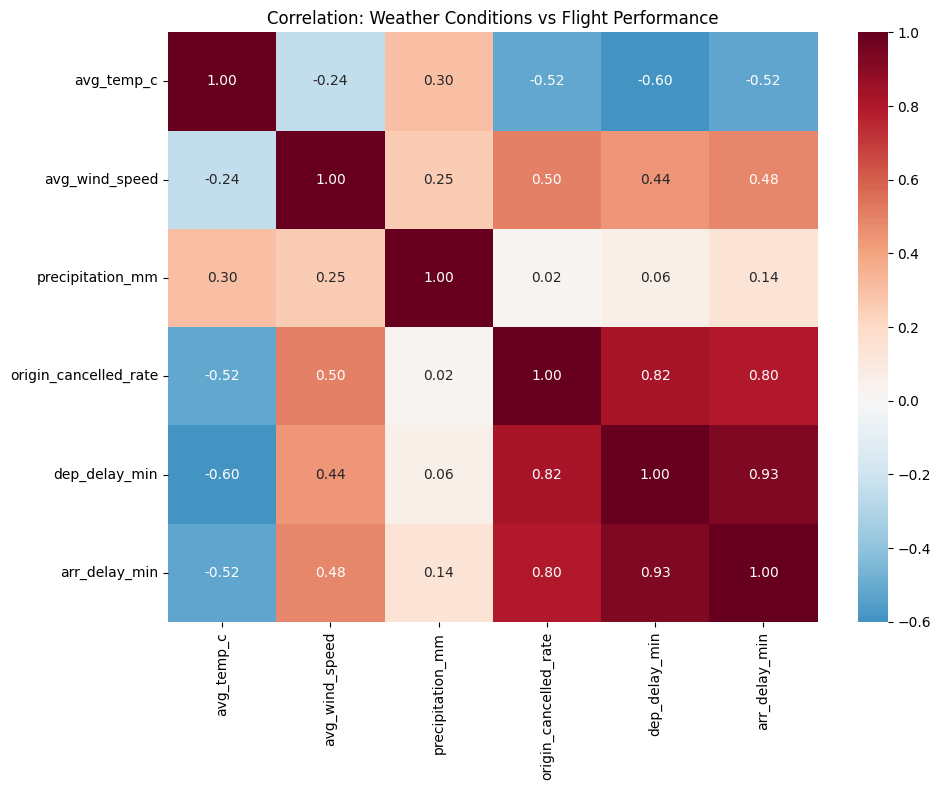

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare numerical columns for correlation
# Timedeltas must be converted to float (minutes) to calculate correlation
df_corr = df.copy()
df_corr['dep_delay_min'] = df_corr['avg_dep_delay'].dt.total_seconds() / 60 # we do it here because correlation won't work with intervals
df_corr['arr_delay_min'] = df_corr['avg_arr_delay'].dt.total_seconds() / 60

# 2. Select the specific columns for the matrix
analysis_cols = [
    'avg_temp_c', 
    'avg_wind_speed', 
    'precipitation_mm', 
    'origin_cancelled_rate', 
    'dep_delay_min', 
    'arr_delay_min'
]

# 3. Calculate the Pearson correlation matrix
correlation_matrix = df_corr[analysis_cols].corr()

# 4. Generate the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='RdBu_r', center=0, fmt=".2f")
plt.title('Correlation: Weather Conditions vs Flight Performance')
plt.tight_layout()
plt.savefig('weather_flight_heatmap.png')

# Display the raw correlation values
print(correlation_matrix[['origin_cancelled_rate', 'dep_delay_min']])

## INTERPRETATION: 
**1. The "Cold" Factor (`avg_temp_c`)**
There is a strong negative correlation between temperature and delays/cancellations (around -0.52 to -0.60).

**Interpretation**: As temperatures dropped (became more negative), flight cancellations and departure delays significantly increased. The value of -0.60 for dep_delay_min suggests that the extreme cold was a major reason for planes being held at the gate (likely for de-icing or equipment issues).

**2. The "Wind" Factor (`avg_wind_speed`)**
There is a moderate positive correlation (0.44 to 0.50) between wind speed and disruptions.

**Interpretation**: Higher wind speeds are directly linked to higher cancellation rates. While not as dominant as temperature, wind clearly played a supporting role in grounded flights.

**3. The "Precipitation" Surprise (`precipitation_mm`)**
Surprisingly, precipitation has a very weak correlation (0.02 to 0.14) with cancellations and delays.

**Insight**: This suggests that "wet" weather (rain/snow volume) wasn't the bottleneck. It was likely the temperature (freeze) and wind (safety) rather than the actual amount of falling snow or rain that caused the chaos.

In [23]:
# Table with Analysis per airport

airport_event_compare = df.groupby(["airport_code", "period"])[[
    "origin_cancelled_rate",
    "total_cancelled_num",
    "avg_dep_delay",
    "avg_temp_c",
    "avg_wind_speed"
]].mean().round(2)

airport_event_compare

/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_80399/482054598.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].mean().round(2)


origin_cancelled_rate  total_cancelled_num  \
airport_code period                                                  
ATL          event                      10.99                11.14   
             non_event                   0.24                 0.29   
BOS          event                      11.96                76.71   
             non_event                   0.80                 6.05   
EWR          event                      11.40                79.29   
             non_event                   0.40                 3.14   
JFK          event                      12.59                78.43   
             non_event                   0.29                 2.43   
ORD          event                      14.54               198.14   
             non_event                   0.53                 7.14   

                                avg_dep_delay  avg_temp_c  avg_wind_speed  
airport_code period                                                        
ATL          event     0 days 00:38:13.670070       -0.06           15.06  
             non_event 0 days 00:14:01.250010       10.44           12.92  
BOS          event     0 days 00:42:57.000569       -1.13           23.81  
             non_event 0 days 00:12:24.695182        3.79           21.12  
EWR          event     0 days 00:54:52.023722       -1.37           22.13  
             non_event 0 days 00:15:03.747379        4.83           16.20  
JFK          event     0 days 00:49:33.649700       -1.73           27.73  
             non_event 0 days 00:12:33.419265        4.54           20.75  
ORD          event     0 days 00:55:02.312605       -9.94           22.00  
             non_event 0 days 00:11:30.291425        0.30           15.75

# H2 OVERALL RESULTS SUMMARY

Flight performance deteriorated significantly during the event period.
- cancellation rates increased
- total cancellations increased
- eparture delays increased

---

# Main takeaway:
Winter Storm Elliott is clearly visible in the weather data and coincides with significantly worse flight performance. The strongest drivers of disruption appear to be extreme cold and wind rather than precipitation alone.